# K-Means from Scratch — Distance Metrics

NumPy K-means with Euclidean, Manhattan and Chebyshev distance on Iris, scored by majority-label cluster accuracy.

# （1)K-means Function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

class KMeans:
    def __init__(self, n_clusters=3, distance='euclidean', max_iter=300, random_state=42):
        self.n_clusters = n_clusters
        self.distance = distance
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids = None
        self.labels = None
    
    def _calculate_distance(self, X, centroids):
        if self.distance == 'euclidean':
            return np.sqrt(((X[:, np.newaxis] - centroids) ** 2).sum(axis=2))
        elif self.distance == 'manhattan':
            return np.abs(X[:, np.newaxis] - centroids).sum(axis=2)
        elif self.distance == 'chebyshev':
            return np.abs(X[:, np.newaxis] - centroids).max(axis=2)
        else:
            raise ValueError("distance error")
    
    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples = X.shape[0]
        indices = np.random.choice(n_samples, self.n_clusters, replace=False)
        self.centroids = X[indices].copy()
        
        for _ in range(self.max_iter):
            distances = self._calculate_distance(X, self.centroids)
            self.labels = np.argmin(distances, axis=1)
            
            new_centroids = np.array([X[self.labels == k].mean(axis=0) 
                                     for k in range(self.n_clusters)])
            
            if np.allclose(self.centroids, new_centroids):
                break
                
            self.centroids = new_centroids
        
        return self

# Evaluation and Plot function

In [2]:
def evaluate_clustering(y_true, y_pred):
    label_map = {}
    for cluster in np.unique(y_pred):
        mask = y_pred == cluster
        if mask.any():
            cluster_labels = y_true[mask]
            unique, counts = np.unique(cluster_labels, return_counts=True)
            label_map[cluster] = unique[np.argmax(counts)]
    
    y_mapped = np.array([label_map[label] for label in y_pred])
    accuracy = np.mean(y_mapped == y_true)
    return accuracy, y_mapped

def plot_clusters(X, y_pred, feature_indices, title):
    colors = ['red', 'blue', 'green']
    for i in range(3):
        mask = y_pred == i
        plt.scatter(X[mask, feature_indices[0]], X[mask, feature_indices[1]], 
                   color=colors[i], alpha=0.7, label=f'Cluster {i}')
    
    plt.xlabel('Sepal length')
    plt.ylabel('Sepal width')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)

# (2) 

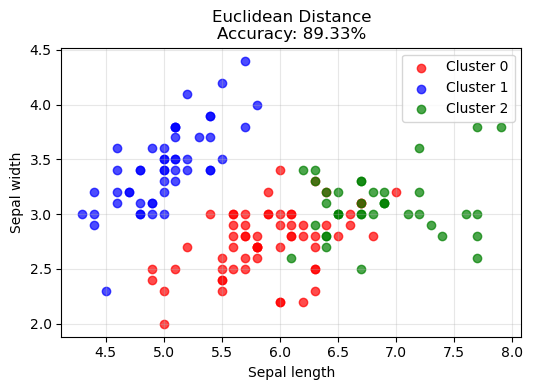

accuracy of Euclidean   : 89.33%


In [3]:
# load data
iris = load_iris()
X = iris.data
y_true = iris.target

# feature setting
features = [0, 1]  # sepal length, sepal width

# distance setting
distances = ['euclidean']
accuracies = []

# plot
plt.figure(figsize=(15, 4))

for i, distance in enumerate(distances):
    kmeans = KMeans(n_clusters=3, distance=distance, random_state=42)
    kmeans.fit(X)
    
    accuracy, _ = evaluate_clustering(y_true, kmeans.labels)
    accuracies.append(accuracy)
    
    plt.subplot(1, 3, i + 1)
    plot_clusters(X[:, features], kmeans.labels, [0, 1], 
                  f'{distance.capitalize()} Distance\nAccuracy: {accuracy:.2%}')

plt.tight_layout()
plt.show()

#  accuracies
for i, distance in enumerate(distances):
    print(f"accuracy of {distance.capitalize():<12}: {accuracies[i]:.2%}")

# (3)

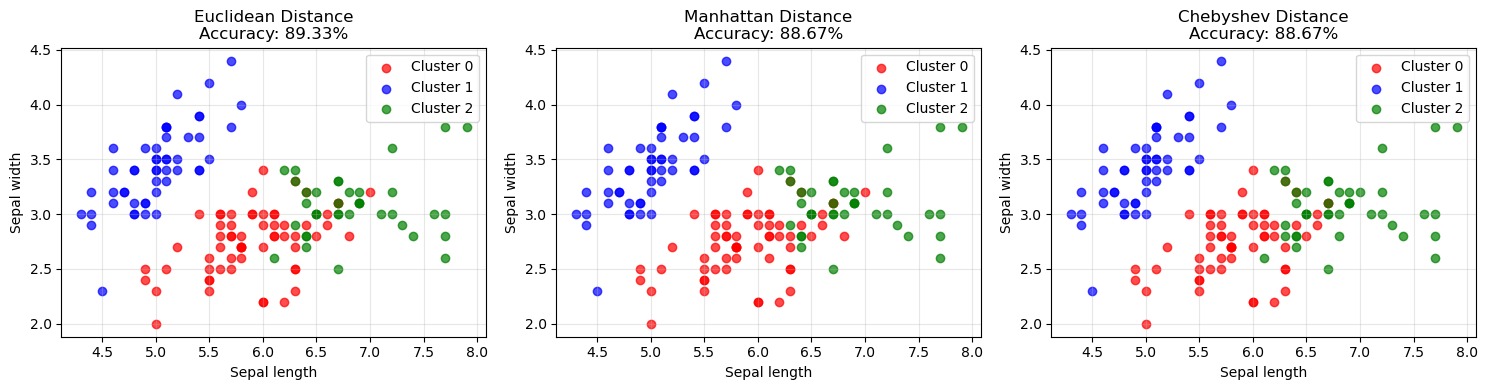

accuracy of Euclidean   : 89.33%
accuracy of Manhattan   : 88.67%
accuracy of Chebyshev   : 88.67%


In [4]:
# load data
iris = load_iris()
X = iris.data
y_true = iris.target

# feature setting
features = [0, 1]  # sepal length, sepal width

# distance setting
distances = ['euclidean', 'manhattan', 'chebyshev']
accuracies = []

# plot
plt.figure(figsize=(15, 4))

for i, distance in enumerate(distances):
    kmeans = KMeans(n_clusters=3, distance=distance, random_state=42)
    kmeans.fit(X)
    
    accuracy, _ = evaluate_clustering(y_true, kmeans.labels)
    accuracies.append(accuracy)
    
    plt.subplot(1, 3, i + 1)
    plot_clusters(X[:, features], kmeans.labels, [0, 1], 
                  f'{distance.capitalize()} Distance\nAccuracy: {accuracy:.2%}')

plt.tight_layout()
plt.show()

#  accuracies
for i, distance in enumerate(distances):
    print(f"accuracy of {distance.capitalize():<12}: {accuracies[i]:.2%}")